# A dívida só cresce quando há déficit primário?

**Grupo G04&** — João Gabriel Daquino • Vinicius Nascimento
Programação para Economistas — Mackenzie CCSA — 2026/2

> **A frase do trabalho.** Superávit primário não basta para a dívida cair: entre dez/2007 e set/2026, a dívida bruta
> subiu em média 5,43 pontos do PIB em 12 meses nos meses de déficit primário acima de 2% e caiu 1,51 ponto nos de
> superávit acima de 2%, mas em 38 dos 104 meses com superávit ela subiu mesmo assim.

**Dados:** Banco Central do Brasil, SGS. Três séries mensais em % do PIB: dívida bruta do governo geral (13762),
resultado primário do setor público consolidado em 12 meses (5793) e juros nominais em 12 meses (5760).
Período: dez/2006 a set/2026 (238 meses). Acesso em 11/11/2026.

## 0. Bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Ler as três séries

In [2]:
url_dbgg  = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.13762/dados?formato=csv&dataInicial=01/12/2006&dataFinal=30/09/2026"
url_prim  = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.5793/dados?formato=csv&dataInicial=01/12/2006&dataFinal=30/09/2026"
url_juros = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.5760/dados?formato=csv&dataInicial=01/12/2006&dataFinal=30/09/2026"

dbgg  = pd.read_csv(url_dbgg,  sep=";", decimal=",")
prim  = pd.read_csv(url_prim,  sep=";", decimal=",")
juros = pd.read_csv(url_juros, sep=";", decimal=",")

print("dívida:  ", dbgg.shape)
print("primário:", prim.shape)
print("juros:   ", juros.shape)
dbgg.head()

dívida:   (238, 2)
primário: (238, 2)
juros:    (238, 2)


,data,valor
0,01/12/2006,55.48
1,01/01/2007,56.17
2,01/02/2007,56.90
3,01/03/2007,57.24
4,01/04/2007,57.17


## 2. Diagnóstico antes de limpar

In [3]:
print(dbgg.dtypes)
print(dbgg.isna().sum())
print("linhas repetidas na dívida:  ", dbgg.duplicated().sum())
print("linhas repetidas no primário:", prim.duplicated().sum())
print("linhas repetidas nos juros:  ", juros.duplicated().sum())
print(prim.isna().sum())
print(juros.isna().sum())

data      object
valor    float64
dtype: object
data     0
valor    0
dtype: int64
linhas repetidas na dívida:   0
linhas repetidas no primário: 0
linhas repetidas nos juros:   0
data     0
valor    0
dtype: int64
data     0
valor    0
dtype: int64


## 3. Nomes que dá para digitar

In [4]:
dbgg.columns  = ["data", "dbgg"]
prim.columns  = ["data", "nfsp_primario"]
juros.columns = ["data", "juros"]
print(dbgg.columns.tolist(), prim.columns.tolist(), juros.columns.tolist())

['data', 'dbgg'] ['data', 'nfsp_primario'] ['data', 'juros']


## 4. Colocar as três séries lado a lado

In [5]:
print("datas iguais (dívida x primário):", (dbgg["data"] == prim["data"]).sum())
print("datas iguais (dívida x juros):   ", (dbgg["data"] == juros["data"]).sum())

tabela = pd.DataFrame({
    "data": list(dbgg["data"]),
    "dbgg": list(dbgg["dbgg"]),
    "nfsp_primario": list(prim["nfsp_primario"]),
    "juros": list(juros["juros"]),
})
print(tabela.shape)
tabela.head()

datas iguais (dívida x primário): 238
datas iguais (dívida x juros):    238
(238, 4)


,data,dbgg,nfsp_primario,juros
0,01/12/2006,55.48,-3.15,6.72
1,01/01/2007,56.17,-3.49,6.50
2,01/02/2007,56.90,-3.50,6.35
3,01/03/2007,57.24,-3.41,6.32
4,01/04/2007,57.17,-3.41,6.24


In [6]:
tabela.to_csv("dados.csv", index=False)

## 5. A partir daqui, tudo sai do arquivo entregue

In [7]:
tabela = pd.read_csv("dados.csv")

tabela["primario"] = tabela["nfsp_primario"] * -1
tabela["data"] = pd.to_datetime(tabela["data"], format="%d/%m/%Y")

df = tabela[["data", "dbgg", "primario", "juros"]]
print(df.shape)
print(df.dtypes)
df.head(10)

(238, 4)
data        datetime64[ns]
dbgg               float64
primario           float64
juros              float64
dtype: object


,data,dbgg,primario,juros
0,2006-12-01,55.48,3.15,6.72
1,2007-01-01,56.17,3.49,6.50
2,2007-02-01,56.90,3.50,6.35
3,2007-03-01,57.24,3.41,6.32
4,2007-04-01,57.17,3.41,6.24
5,2007-05-01,57.91,3.45,6.53
6,2007-06-01,58.23,3.39,6.21
7,2007-07-01,58.32,3.40,6.17
8,2007-08-01,58.46,3.24,5.94
9,2007-09-01,57.88,3.21,6.06


## 6. O indicador e as faixas


In [8]:
data_lista     = list(df["data"])
dbgg_lista     = list(df["dbgg"])
primario_lista = list(df["primario"])
juros_lista    = list(df["juros"])

meses = []
var_dbgg = []
primario = []
juros_m = []
faixas = []

for i in range(12, len(dbgg_lista)):
    meses.append(data_lista[i])
    var_dbgg.append(dbgg_lista[i] - dbgg_lista[i - 12])
    primario.append(primario_lista[i])
    juros_m.append(juros_lista[i])

    if primario_lista[i] <= -2:
        faixas.append("1. Déficit > 2%")
    elif primario_lista[i] <= 0:
        faixas.append("2. Déficit 0 a 2%")
    elif primario_lista[i] <= 2:
        faixas.append("3. Superávit 0 a 2%")
    else:
        faixas.append("4. Superávit > 2%")

analise = pd.DataFrame({
    "data": meses,
    "var_dbgg": var_dbgg,
    "primario": primario,
    "juros": juros_m,
    "faixa": faixas,
})

analise["deficit_nominal"] = analise["juros"] - analise["primario"]

print(analise.shape)
analise.head()

(226, 6)


,data,var_dbgg,primario,juros,faixa,deficit_nominal
0,2007-12-01,1.24,3.24,5.98,4. Superávit > 2%,2.74
1,2008-01-01,1.34,3.39,5.89,4. Superávit > 2%,2.50
2,2008-02-01,0.14,3.43,5.99,4. Superávit > 2%,2.56
3,2008-03-01,-0.15,3.63,5.85,4. Superávit > 2%,2.22
4,2008-04-01,-0.65,3.61,5.86,4. Superávit > 2%,2.25


## 7. Tabela descritiva por faixa

In [9]:
resumo = analise.groupby("faixa")["var_dbgg"].agg(["mean", "std", "min", "max"]).round(2)
resumo["meses"] = analise.groupby("faixa").size()
resumo["primario_medio"] = analise.groupby("faixa")["primario"].mean().round(2)
resumo["juros_medios"] = analise.groupby("faixa")["juros"].mean().round(2)
resumo["deficit_nominal_medio"] = analise.groupby("faixa")["deficit_nominal"].mean().round(2)
resumo

,mean,std,min,max,meses,primario_medio,juros_medios,deficit_nominal_medio
faixa,,,,,,,,
1. Déficit > 2%,5.43,3.29,-3.25,12.50,48,-3.86,5.99,9.84
2. Déficit 0 a 2%,2.57,3.68,-8.14,9.34,74,-0.94,6.58,7.52
3. Superávit 0 a 2%,-1.84,4.18,-9.95,5.97,52,1.35,5.11,3.77
4. Superávit > 2%,-1.51,2.74,-7.44,2.89,52,2.89,5.31,2.42


In [10]:
print("Todos os meses:", len(analise), "| variação média:", round(analise["var_dbgg"].mean(), 2))

Todos os meses: 226 | variação média: 1.22


## 8. Respondendo a pergunta: superávit garante queda?

In [11]:
superavit = analise["primario"] > 0
deficit = analise["primario"] <= 0
subiu = analise["var_dbgg"] > 0
caiu = analise["var_dbgg"] < 0

print("Meses com superávit:", superavit.sum())
print("   ... e a dívida subiu mesmo assim:", (superavit & subiu).sum())
print("Meses com déficit:", deficit.sum())
print("   ... e a dívida caiu mesmo assim:", (deficit & caiu).sum())
print("Meses com déficit nominal (juros > superávit):", (analise["deficit_nominal"] > 0).sum(), "de", len(analise))

Meses com superávit: 104
   ... e a dívida subiu mesmo assim: 38
Meses com déficit: 122
   ... e a dívida caiu mesmo assim: 15
Meses com déficit nominal (juros > superávit): 226 de 226


In [12]:
print("variação da dívida x primário:       ", round(analise["var_dbgg"].corr(analise["primario"]), 2))
print("variação da dívida x déficit nominal:", round(analise["var_dbgg"].corr(analise["deficit_nominal"]), 2))

variação da dívida x primário:        -0.65
variação da dívida x déficit nominal: 0.71


## 9. Gráfico 1 — barras: variação média da dívida por faixa



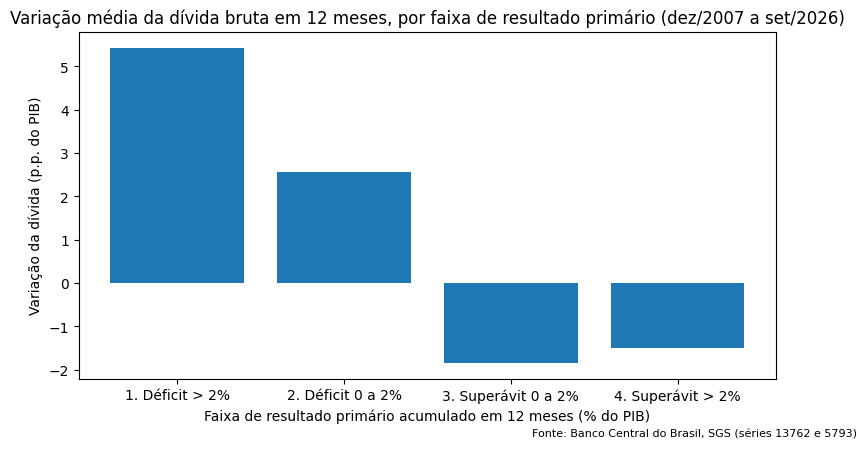

In [13]:
barras = resumo.reset_index()

plt.figure(figsize=(9, 4.5))
plt.bar(barras["faixa"], barras["mean"])
plt.title("Variação média da dívida bruta em 12 meses, por faixa de resultado primário (dez/2007 a set/2026)")
plt.xlabel("Faixa de resultado primário acumulado em 12 meses (% do PIB)")
plt.ylabel("Variação da dívida (p.p. do PIB)")
plt.figtext(0.99, -0.02, "Fonte: Banco Central do Brasil, SGS (séries 13762 e 5793)", ha="right", fontsize=8)
plt.show()

## 10. Gráfico 2 — linhas: as três séries no tempo



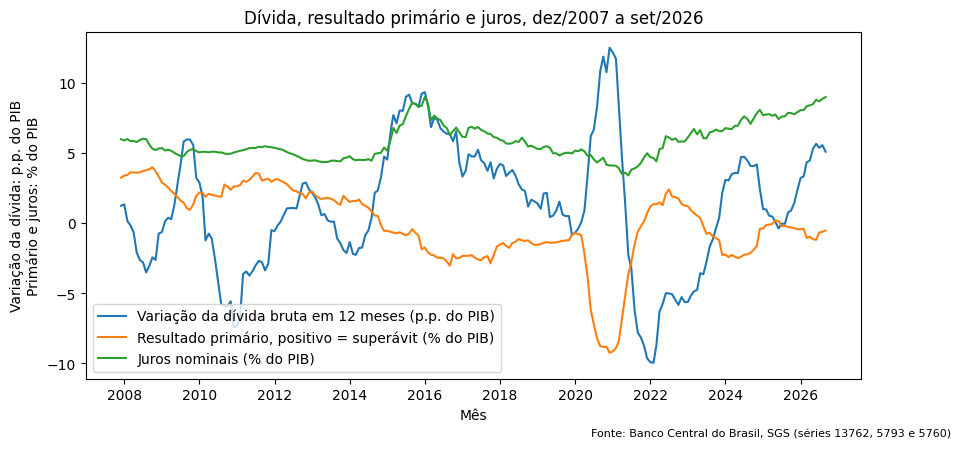

In [14]:
plt.figure(figsize=(10, 4.5))
plt.plot(analise["data"], analise["var_dbgg"], label="Variação da dívida bruta em 12 meses (p.p. do PIB)")
plt.plot(analise["data"], analise["primario"], label="Resultado primário, positivo = superávit (% do PIB)")
plt.plot(analise["data"], analise["juros"], label="Juros nominais (% do PIB)")
plt.title("Dívida, resultado primário e juros, dez/2007 a set/2026")
plt.xlabel("Mês")
plt.ylabel("Variação da dívida: p.p. do PIB\nPrimário e juros: % do PIB")
plt.legend()
plt.figtext(0.99, -0.02, "Fonte: Banco Central do Brasil, SGS (séries 13762, 5793 e 5760)", ha="right", fontsize=8)
plt.show()

## 11. Conclusão

Em média, a dívida sobe com déficit e cai com superávit, e quanto maior o déficit, mais ela sobe.
Mas a resposta à pergunta é não: superávit primário não basta. Em 38 dos 104 meses com superávit a dívida
ainda cresceu, e o governo teve déficit nominal em todos os 226 meses, ou seja, os juros sempre superaram o superávit.
Tudo aqui é descritivo: a variação da dívida também depende do crescimento do PIB, da inflação e do câmbio,
que esta análise não separa.